# Examen — Módulo 1: Preparación de datos
**Aprendizaje Supervisado · Evaluación de las sesiones 1–3** (EDA, preprocesamiento, ingeniería y selección de variables)

**Instrucciones**

- Trabajo **individual**. Duración sugerida: **120 minutos**. Material permitido: tus notas, la presentación y la documentación oficial de pandas, scikit-learn y matplotlib.
- Escribe tu nombre en la primera celda de código (`NOMBRE`).
- Sustituye cada `...` (marcado con ✏️) por tu código. En las preguntas con **“Respuesta:”**, escribe tu explicación en la celda de texto que sigue (editando la celda de Markdown).
- Antes de entregar, ejecuta **Kernel → Reiniciar y ejecutar todo**; el notebook debe correr de principio a fin sin errores.
- Los datos son simulados y se generan con semilla fija: tus resultados deben ser reproducibles.
- Se evalúa tanto el **código** como la **calidad de la justificación**. Las respuestas escritas deben ser breves y precisas.

| Parte | Tema | Puntos |
|---|---|---|
| I | Análisis exploratorio de datos | 30 |
| II | Preprocesamiento de datos | 35 |
| III | Ingeniería y selección de variables | 35 |
| | **Total** | **100** |


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder,
                                   OrdinalEncoder, PolynomialFeatures)
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.feature_selection import (VarianceThreshold, SelectKBest, f_classif, mutual_info_classif,
                                       RFE, RFECV, SelectFromModel)
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

NOMBRE = "ANDRÉS ARCOS ESCUDERO"        # ✏️ escribe tu nombre completo


In [2]:
# ---------------------------------------------------------------------------------------------
# Generadores de datos (NO los modifiques; no necesitas leerlos para resolver el examen)
# ---------------------------------------------------------------------------------------------
def genera_viviendas(n=1200, seed=2026):
    """Viviendas en venta en una ciudad (datos simulados). Precio en miles de pesos."""
    r = np.random.default_rng(seed)
    zona = r.choice(["Norte", "Centro", "Poniente", "Oriente", "Sur", "Costa"], n, p=[.30, .15, .22, .14, .17, .02])
    acab = r.choice(["Básico", "Medio", "Alto", "Premium"], n, p=[.30, .40, .22, .08])
    sup = np.exp(r.normal(np.log(110), .38, n)).round(0)
    rec = np.clip(np.round(sup / 45 + r.normal(0, .6, n)), 1, 6).astype(int)
    ant = np.clip(r.gamma(1.6, 9, n), 0, 70).round(0)
    dist = np.round(r.gamma(2.2, 3.2, n), 1)
    zef = pd.Series(zona).map({"Norte": .25, "Centro": .05, "Poniente": .10, "Oriente": -.20, "Sur": -.30, "Costa": .55}).values
    aef = pd.Series(acab).map({"Básico": 0, "Medio": .18, "Alto": .40, "Premium": .75}).values
    lp = 1.2 + .85 * np.log(sup) + zef + aef - .008 * ant - .035 * dist + .04 * rec + r.normal(0, .17, n)
    precio = (np.exp(lp) * 25).round(0)
    idx = r.choice(n, 10, replace=False)
    precio[idx] *= r.uniform(3.5, 6, 10)
    df = pd.DataFrame(dict(zona=zona, acabados=acab, superficie_m2=sup, recamaras=rec,
                           antiguedad_anios=ant, dist_centro_km=dist, precio_miles=precio.round(0)))
    pm = np.where(np.isin(zona, ["Sur", "Oriente"]), .22, .04)
    df.loc[r.random(n) < pm, "antiguedad_anios"] = np.nan
    df.loc[r.random(n) < .04, "superficie_m2"] = np.nan
    return df


def genera_biomarcadores(n=400, seed=7):
    """400 pacientes, 26 mediciones de laboratorio y un diagnóstico y ∈ {0, 1} (datos simulados)."""
    r = np.random.default_rng(seed)
    y = r.integers(0, 2, n)
    s = 2 * y - 1
    a = r.normal(0.9 * s, 1.0)
    b = 100 + 15 * r.normal(0.6 * s, 1.0)
    c = 0.02 * r.normal(0.8 * s, 1.0)
    cuad = np.where(y == 1, r.choice([-1, 1], n) * r.normal(1.6, .35, n), r.normal(0, .45, n))
    a_copia = a + r.normal(0, .15, n)
    casi = 5 + 1e-3 * r.normal(0, 1, n)
    ruido = r.normal(0, 1, (n, 20)) * r.choice([1, 1, 1, 10, 50], 20)
    cols = {"lin_a": a, "lin_b": b, "lin_c": c, "cuad": cuad, "lin_a_copia": a_copia, "casi_const": casi}
    for i in range(20):
        cols[f"ruido_{i + 1:02d}"] = ruido[:, i]
    return pd.DataFrame(cols), pd.Series(y, name="y")


---
## Parte I — Análisis exploratorio de datos (30 puntos)

Trabajarás con `viv`: **1 200 viviendas en venta** de una ciudad (datos simulados).
Variables: `zona` y `acabados` (categóricas; `acabados` es ordinal: Básico < Medio < Alto < Premium), `superficie_m2`, `recamaras`,
`antiguedad_anios`, `dist_centro_km` y el objetivo `precio_miles` (miles de pesos). Hay valores faltantes.

In [3]:
viv = genera_viviendas()
NUM = ["superficie_m2", "recamaras", "antiguedad_anios", "dist_centro_km", "precio_miles"]
print(viv.shape)
viv.head()

(1200, 7)


,zona,acabados,superficie_m2,recamaras,antiguedad_anios,dist_centro_km,precio_miles
0,Norte,Medio,74.0,2,25.0,8.1,4289.0
1,Poniente,Medio,166.0,4,14.0,9.4,7465.0
2,Poniente,Premium,211.0,4,7.0,2.1,16996.0
3,Centro,Medio,153.0,4,30.0,3.4,6301.0
4,Centro,Básico,101.0,2,0.0,9.5,4444.0


### Pregunta I.1 · Asimetría y curtosis  *(4 pts)*

Calcula la **asimetría** y la **curtosis (excedente)** de las cinco variables numéricas `NUM` y guarda en `mas_asimetrica` el *nombre* de la variable con mayor asimetría.

In [4]:
asim = viv[NUM].skew()          # ✏️ Series con la asimetría de cada variable de NUM
curt = viv[NUM].kurt()              # ✏️ Series con la curtosis excedente de cada variable de NUM
mas_asimetrica = asim.abs().idxmax()   # ✏️ nombre (str) de la variable más asimétrica

print(pd.DataFrame({"asimetría": asim, "curtosis": curt}).round(2))
print("Más asimétrica:", mas_asimetrica)

                  asimetría  curtosis
superficie_m2          1.00      1.42
recamaras              0.57      0.10
antiguedad_anios       1.41      2.36
dist_centro_km         1.16      1.87
precio_miles           3.38     22.95
Más asimétrica: precio_miles


### Pregunta I.2 · Interpretar la forma de `precio_miles`  *(3 pts)*

Observa la media y la mediana del precio y su histograma. En **3 a 5 líneas**: ¿qué forma tiene la distribución según la asimetría y la curtosis? ¿Qué medida de centro describiría mejor un precio “típico” y por qué?

media = 5,271   mediana = 4,504   cutosis = 23   asmetría = 3


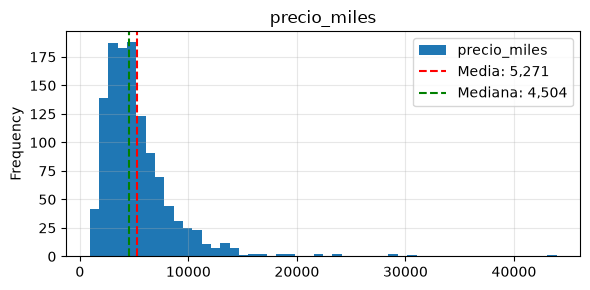

In [5]:
print(f"media = {viv.precio_miles.mean():,.0f}   mediana = {viv.precio_miles.median():,.0f}   cutosis = {viv.precio_miles.kurt():,.0f}   asmetría = {viv.precio_miles.skew():,.0f}")
plt.figure(figsize=(6, 3))
viv.precio_miles.plot.hist(bins=50, title="precio_miles")
plt.axvline(viv.precio_miles.mean(), color='red', linestyle='--', linewidth=1.5, label=f'Media: {viv.precio_miles.mean():,.0f}')
plt.axvline(viv.precio_miles.median(), color='green', linestyle='--', linewidth=1.5, label=f'Mediana: {viv.precio_miles.median():,.0f}')
plt.legend()
plt.tight_layout()
plt.show()

**Respuesta:**

La gráfica muestra que tiene una asimetría positiva (3) con la presencia de datos atípicos a la derecha muy alejados, así mismo, tiene una curtosis alta (23), esto indía que la curtosis se representaría con una forma de pico con una concentración de datos cerca de la media pero por la presencia de valores atípicos mostraría una cola larga.

Entre la media y la mediana, se aprecia que la mediana representa un mejor centro sobre la gráfica lo que indicaría que un precio típico estaría más cercano a los 4 504. 


### Pregunta I.3 · Regla del IQR  *(5 pts)*

Escribe la función `atipicos_iqr(s, k=1.5)` que, dada una Series `s`, devuelva una Series booleana que marque como atípicos los valores fuera de $[Q_1 - k\,\mathrm{IQR},\; Q_3 + k\,\mathrm{IQR}]$ (ignora los `NaN`). Después cuenta los atípicos de cada variable de `NUM`.

In [6]:
def atipicos_iqr(s, k=1.5):
    s_clean = s.dropna()
    Q1 = s_clean.quantile(0.25)
    Q3 = s_clean.quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - k * IQR
    lim_sup = Q3 + k * IQR
    return s.notna() & ((s < lim_inf) | (s > lim_sup))


n_atip = {variable: int(atipicos_iqr(viv[variable]).sum()) for variable in NUM}    # ✏️ dict {variable: número de atípicos} para cada variable de NUM
print(n_atip)

{'superficie_m2': 20, 'recamaras': 78, 'antiguedad_anios': 37, 'dist_centro_km': 25, 'precio_miles': 57}


### Pregunta I.4 · El logaritmo y los atípicos  *(4 pts)*

Crea `log_precio = np.log(viv.precio_miles)`, calcula su asimetría y cuántos atípicos marca la regla del IQR. Luego responde en **3 a 4 líneas**: ¿la transformación resolvió el problema de los atípicos? Entre eliminarlos, dejarlos o transformarlos, ¿qué harías con las viviendas más caras y por qué? (Recuerda cómo se generó el dato: hay viviendas con precios muy superiores al de su tipo.)

In [7]:
log_precio = np.log(viv.precio_miles)                     # ✏️
asim_log = log_precio.skew()                               # ✏️ asimetría de log_precio
n_atip_log = int(atipicos_iqr(log_precio).sum())           # ✏️ número de atípicos de log_precio según la regla del IQR
print(f"asimetría: {asim_log:.2f}   atípicos: {n_atip_log}")

asimetría: 0.22   atípicos: 14


**Respuesta:**

Después de aplicar la transformación, la asimetría paso de 3 a 0.22 lo que representa que está muy cerca de ser simétrica; y los valores atípicos bajaron de 57 a 14 con respecto al rango intercuartilico, por lo tanto se puede decir que la tranformación funciono.

En a que hacer con los datos atípicos, tendría que evaluar si mi modelo es sensible a estos valores, si es así, entonces podría mantenerlos con la transformación, ya que pueden representar viviendas de alta gama.


### Pregunta I.5 · Pearson, Spearman y transformaciones  *(6 pts)*

Calcula, entre el precio y `superficie_m2`, cuatro coeficientes y guárdalos en el dict `r`:
`"pearson_crudo"` (precio sin transformar), `"pearson_log"` (con `log_precio`), `"spearman_crudo"` y `"spearman_log"`.
Después explica en **3 a 4 líneas**: (a) por qué `spearman_crudo` y `spearman_log` coinciden, y (b) por qué `pearson_crudo` y `pearson_log` no.

In [8]:
d = pd.DataFrame({"precio": viv.precio_miles, "log_precio": log_precio, "superficie": viv.superficie_m2})

r = {
    "pearson_crudo":  float(d["precio"].corr(d["superficie"], method="pearson")),
    "pearson_log":    float(d["log_precio"].corr(d["superficie"], method="pearson")),
    "spearman_crudo": float(d["precio"].corr(d["superficie"], method="spearman")),
    "spearman_log":   float(d["log_precio"].corr(d["superficie"], method="spearman")),
}
print({k: round(v, 3) for k, v in r.items()})

{'pearson_crudo': 0.546, 'pearson_log': 0.616, 'spearman_crudo': 0.637, 'spearman_log': 0.637}


**Respuesta:**

(a) Por qué coinciden `spearman_crudo` y `spearman_log`: porque el coeficiente de Spearman trbaja con posiciones ordenadas, sin importar que grande es la diferencia entre los valores, este los ordena de mayor a menor. Esto indica que aún con la transfomación los valores siguen conservando el mismo orden.

(b) Por qué no coinciden `pearson_crudo` y `pearson_log`: a diferencia de Sperman el coeficinete de Pearson, si trabaja con los valores de los datos por lo tanto un outlier puede cambiar el resultado del coeficiente. En este caso cuando aplicamos la transformación se prodrá observar que sus valores cambian. 


### Pregunta I.6 · Verdadero o falso  *(4 pts)*

Marca cada afirmación como `True` (verdadera) o `False` (falsa). Cada acierto vale 1 punto; no hay penalización por error.

- **a)** Si el coeficiente de correlación de Pearson entre $X$ e $Y$ es 0, entonces $X$ e $Y$ son independientes.
- **b)** La mediana es más robusta que la media frente a valores atípicos.
- **c)** Una correlación de 0.9 entre las ventas de helado y los ahogamientos demuestra que el helado causa ahogamientos.
- **d)** Una curtosis excedente positiva indica colas más pesadas que las de una distribución normal.

In [9]:
resp_VF = {"a": False, "b": True, "c": False, "d": True}     # ✏️ reemplaza None por True o False
print(resp_VF)

{'a': False, 'b': True, 'c': False, 'd': True}


### Pregunta I.7 · Matriz de correlación y multicolinealidad  *(4 pts)*

Calcula la matriz de correlación de Pearson de `superficie_m2`, `recamaras`, `antiguedad_anios`, `dist_centro_km` y `log_precio`, dibújala como mapa de calor (con barra de color y etiquetas) y guarda en `par` la tupla con los nombres de las **dos variables explicativas** (sin contar `log_precio`) más correlacionadas entre sí en valor absoluto. En **2 a 3 líneas**: ¿por qué sería un problema meter ambas en una regresión lineal y qué harías?


Par de variables más correlacionadas: ('superficie_m2', 'recamaras')


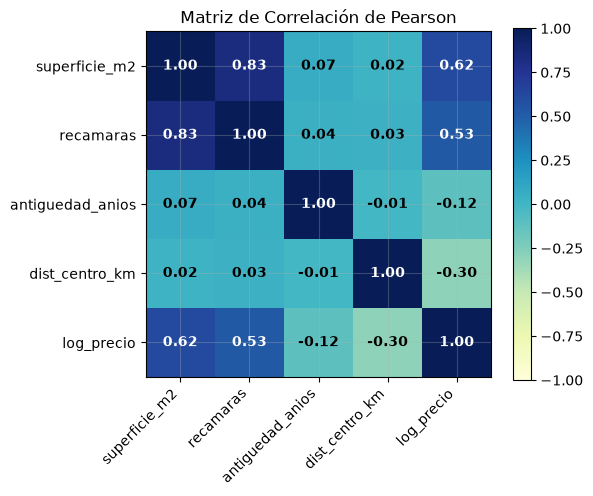

In [10]:
cols = ["superficie_m2", "recamaras", "antiguedad_anios", "dist_centro_km"]
d_corr = viv[cols].copy()
d_corr["log_precio"] = log_precio

C = d_corr.corr(method="pearson")   # ✏️ matriz de correlación de cols + log_precio (use viv y log_precio)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(C, cmap="YlGnBu", vmin=-1, vmax=1)
fig.colorbar(im, ax=ax)

ax.set_xticks(range(len(C.columns)))
ax.set_yticks(range(len(C.columns)))
ax.set_xticklabels(C.columns, rotation=45, ha="right")
ax.set_yticklabels(C.columns)

for i in range(len(C.columns)):
    for j in range(len(C.columns)):
        val = C.iloc[i, j]
        color_texto = "white" if abs(val) > 0.5 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=color_texto, fontweight="bold")

plt.title("Matriz de Correlación de Pearson")
plt.tight_layout()

C_explicativas = C.loc[cols, cols].abs()

vals_explicativas = C_explicativas.values.copy()
np.fill_diagonal(vals_explicativas, 0)
C_explicativas_sin_diag = pd.DataFrame(vals_explicativas, index=C_explicativas.index, columns=C_explicativas.columns)

max_corr_idx = C_explicativas_sin_diag.unstack().idxmax()
par = (max_corr_idx[0], max_corr_idx[1])

print("\nPar de variables más correlacionadas:", par)

**Respuesta:**

Incluir ambas variables causaría inestabilidad en la estimación de los coeficientes de la regresión lineal (aumenta la error estándar de los coeficientes), haciendo que sean difíciles de interpretar y muy sensibles a pequeños cambios en los datos.

Para solucionar esto, se podría prescindir de una de ellas, se podría conservar únicamente `superficie_m2` que tiene mayor correlación directa con la variable objetivo `log_precio`, o bien utilizar técnicas de regularización (como Ridge o Lasso) para penalizar y estabilizar los coeficientes.

---
## Parte II — Preprocesamiento de datos (35 puntos)

Seguimos con el conjunto `viv`. Ahora el objetivo es **predecir `log(precio_miles)`** con un modelo lineal, cuidando el preprocesamiento.

### Pregunta II.1 · Cuantificar los valores faltantes  *(4 pts)*

Calcula (a) el número y el porcentaje de valores faltantes por columna y (b) la **proporción de faltantes por `zona`** para `antiguedad_anios` y `superficie_m2`.

In [11]:
# (a) Número y porcentaje de valores faltantes por columna
faltantes = pd.DataFrame({
    "n": viv.isna().sum(),
    "%": viv.isna().mean() * 100
})

# (b) Proporción de faltantes por zona para las columnas indicadas
falt_por_zona = viv.groupby("zona")[["antiguedad_anios", "superficie_m2"]].apply(lambda x: x.isna().mean())

print(faltantes[faltantes["n"] > 0])
print("\nProporción por zona (%):")
print((100 * falt_por_zona).round(1))

print(faltantes[faltantes["n"] > 0])
print((100 * falt_por_zona).round(1))

                    n         %
superficie_m2      62  5.166667
antiguedad_anios  107  8.916667

Proporción por zona (%):
          antiguedad_anios  superficie_m2
zona                                     
Centro                 2.2            6.7
Costa                  0.0            4.0
Norte                  3.0            4.0
Oriente               19.1            4.4
Poniente               4.4            5.2
Sur                   21.6            6.6
                    n         %
superficie_m2      62  5.166667
antiguedad_anios  107  8.916667
          antiguedad_anios  superficie_m2
zona                                     
Centro                 2.2            6.7
Costa                  0.0            4.0
Norte                  3.0            4.0
Oriente               19.1            4.4
Poniente               4.4            5.2
Sur                   21.6            6.6


### Pregunta II.2 · Mecanismo de los faltantes  *(3 pts)*

Con lo que observaste en II.1, ¿qué mecanismo (MCAR, MAR o MNAR) es más plausible para `antiguedad_anios` y cuál para `superficie_m2`? Justifica con los números. ¿Qué riesgo habría al **borrar** las filas incompletas?

**Respuesta:**

La variable `antiguedad_anios` está fuertemente correlacionada con la variable observada `zona` (las zonas Sur y Oriente tienen ~20% de faltantes, mientras que las demás tienen < 5%), por lo tanto se debe considerar como MAR.

Para la variable `superficie_m2`, la proporción de valores faltantes osila entre entre 4% y 6.7% en todas las zonas, sugiriendo que la pérdida no depende de otra variable y se puede considerar como MCAR.

Al riesgo al borrar filas incompletas, se introduce un sesgo de selección en el modelo debido a que estaríamos eliminando una gran proporción de viviendas de las zonas Sur y Oriente, perdiendo representatividad de esas regiones además de reducir drásticamente el tamaño de muestra útil.


### Pregunta II.3 · División entrenamiento / prueba  *(5 pts)*

Define `X = viv` sin `precio_miles` e `y = log_precio`. Separa 80 % para entrenamiento y 20 % para prueba (`random_state=0`) **estratificando por `zona`**, y muestra la proporción de cada zona en `X_train` y `X_test`. En **2 líneas**: ¿por qué conviene estratificar en este conjunto?

In [12]:
X = viv.drop(columns=["precio_miles"])
y = log_precio

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=0, stratify=X["zona"]
)
prop = pd.DataFrame({
    "train": X_train["zona"].value_counts(normalize=True),
    "test": X_test["zona"].value_counts(normalize=True)
})

print((100 * prop).round(1))

          train  test
zona                 
Norte      27.4  27.5
Poniente   22.5  22.5
Sur        17.7  17.9
Oriente    15.3  15.0
Centro     15.0  15.0
Costa       2.1   2.1


**Respuesta:**

Conviene estratificar debido a que algunas zonas como 'Costa' tienen una representación minoritaria con un ~2% de la muestra. Sin estratificación, existe un alto riesgo de que estas zonas queden subrepresentadas o completamente ausentes en el conjunto de prueba, impidiendo evaluar correctamente el desempeño del modelo en dichas regiones.

### Pregunta II.4 · Detectar fuga de datos  *(4 pts)*

Un compañero escribe este código para “preparar los datos” y luego evalúa con validación cruzada:

```python
X_num = viv[["superficie_m2", "antiguedad_anios", "dist_centro_km"]]
X_num = SimpleImputer(strategy="mean").fit_transform(X_num)      # (1)
X_num = StandardScaler().fit_transform(X_num)                    # (2)
scores = cross_val_score(Ridge(), X_num, log_precio, cv=5)       # (3)
```

Explica **qué información se filtra** en los pasos (1) y (2), por qué es un problema y cómo lo corregirías (en palabras, sin escribir todo el código).

**Respuesta:**

En los pasos (1) y (2), se filtra la media de todo el conjunto a través de imputar los valores faltantes y también se filtra la media y la desviación estandar al estandarizar los datos.

Esto es un problema por el data leakage, es decir, se estará filtrando información estadística entre los  subconjuntos de los datos de entrenamiento cuando se haga la validación cruzada. 

Se podría corregir con un pipeline que encapsule el preprocesamiento de SimpleImputer y StandarScaler junto con el estimador Ridge y posteriormente evaluarlo durante el cross_val_score.


### Pregunta II.5 · Pipeline de preprocesamiento + modelo  *(10 pts)*

Construye un `Pipeline` que, **sin fuga de datos**, haga:

1. Variables numéricas (`superficie_m2`, `recamaras`, `antiguedad_anios`, `dist_centro_km`): imputación y un escalador de tu elección.
2. Variable nominal `zona`: imputación (por si acaso) y codificación *one-hot* **tolerante a categorías no vistas**.
3. Variable ordinal `acabados`: codificación ordinal respetando Básico < Medio < Alto < Premium.
4. Modelo: `Ridge(alpha=1.0)`.

Evalúa con validación cruzada de 5 particiones **solo con el entrenamiento** (reporta el RMSE medio sobre `log(precio)`), ajusta con todo el entrenamiento y reporta el RMSE en prueba. Justifica en 2 líneas tu elección de imputador y escalador.

In [13]:
NUM_X = ["superficie_m2", "recamaras", "antiguedad_anios", "dist_centro_km"]
NOM = ["zona"]
ORD = ["acabados"]

acabados_order = ["Básico", "Medio", "Alto", "Premium"]

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

nom_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

ord_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(categories=[acabados_order]))
])

pre = ColumnTransformer([
    ("num", num_pipe, NUM_X),
    ("nom", nom_pipe, NOM),
    ("ord", ord_pipe, ORD)
])

modelo = Pipeline([
    ("pre", pre),
    ("reg", Ridge(alpha=1.0))
])

cv = KFold(5, shuffle=True, random_state=0)
scores = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="neg_mean_squared_error")
rmse_cv = np.mean(np.sqrt(-scores))

modelo.fit(X_train, y_train)
preds_test = modelo.predict(X_test)
rmse_test = np.sqrt(mean_squared_error(y_test, preds_test))

print(f"RMSE CV = {rmse_cv:.3f}    RMSE prueba = {rmse_test:.3f}")

RMSE CV = 0.254    RMSE prueba = 0.251


**Respuesta:**

Se eligio la mediana debido a que es más robusta a valores atípicos y asimetría de los datos, lo cual puede ayudar con las variables superficie_m2 y antiguedad_anios.

Y se utilizo RobustScaler previniendo la presencia de registros con valores atípicos extremos, lo que podría comprimir el rango de los valores típicos, como ocurriría con StandarScaler o MinMaxScaler.

### Pregunta II.6 · Escalador y atípicos  *(4 pts)*

Toma `superficie_m2` del conjunto de entrenamiento (imputando antes los `NaN` con la mediana) y **añade un registro mal capturado de 5 000 m²**. Aplica `StandardScaler` y `RobustScaler`. Para cada resultado calcula el **rango intercuartílico** de la variable escalada y su **valor absoluto máximo**. En **2 a 3 líneas**: ¿qué escalador es más sensible a los atípicos y por qué? ¿Para qué tipo de modelos importa escalar?

In [14]:
s = X_train["superficie_m2"].fillna(X_train["superficie_m2"].median())
s = pd.concat([s, pd.Series([5000.0])], ignore_index=True).to_frame()     # añadimos el dato mal capturado

z_std = StandardScaler().fit_transform(s).flatten()
z_rob = RobustScaler().fit_transform(s).flatten()

def resumen(z):
    q1, q3 = np.percentile(z, [25, 75])
    return {"IQR": round(q3 - q1, 3), "|max|": round(np.abs(z).max(), 2)}

print("Standard:", resumen(z_std))
print("Robust:  ", resumen(z_rob))

Standard: {'IQR': np.float64(0.354), '|max|': np.float64(29.78)}
Robust:   {'IQR': np.float64(1.0), '|max|': np.float64(84.28)}


**Respuesta:**

`StandardScaler` es mucho más sensible a los valores atípicos porque utiliza la media y la desviación estándar, que se ven fuertemente arrastradas por valores extremos. `RobustScaler` utiliza la mediana y el rango intercuartílico (IQR), lo cual mantiene el IQR escalado exactamente en 1.0, aislando de forma segura el impacto del atípico en su valor máximo sin distorsionar el resto de los datos.

Escalar es fundamental para modelos basados en distancias (como KNN, K-Means, SVM), algoritmos de optimización por descenso de gradiente (regresiones lineales/logísticas, redes neuronales) y modelos con regularización (como Lasso), donde la escala de las variables afecta directamente la penalización.

### Pregunta II.7 · Categorías no vistas y codificación  *(5 pts)*

Ajusta un `OneHotEncoder` **con el valor por defecto** y otro con `handle_unknown="ignore"` usando solo las filas de `X_train` cuya `zona` **no** sea `Costa`. Luego transforma una vivienda de `Costa` con cada uno: captura el error del primero (`msg_error`) y guarda la fila resultante del segundo (`fila_ignore`).
En **2 líneas**: ¿qué problema aparece si en lugar de *one-hot* codificas `zona` con enteros (0, 1, 2, …) en un modelo lineal?

In [15]:
sin_costa = X_train.loc[X_train["zona"] != "Costa", ["zona"]]
nueva = pd.DataFrame({"zona": ["Costa"]})

msg_error = None
try:
    ohe_defecto = OneHotEncoder(sparse_output=False)
    ohe_defecto.fit(sin_costa)
    ohe_defecto.transform(nueva)
except ValueError as e:
    msg_error = str(e)[:90]

ohe_ignore = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ohe_ignore.fit(sin_costa)
fila_ignore =  ohe_ignore.transform(nueva)

print("Error:", msg_error)
print("Fila con ignore:", fila_ignore)

Error: Found unknown categories ['Costa'] in column 0 during transform
Fila con ignore: [[0. 0. 0. 0. 0.]]


**Respuesta:**

Si codificamos la variable nominal `zona` con enteros (0, 1, 2, ...), un modelo lineal asumirá incorrectamente que existe un orden de jerarquía y una relación de distancia constante entre las zonas (por ejemplo, que la zona 2 es el doble de la zona 1 o más cercana a esta que la zona 0), distorsionando por completo la estimación de los coeficientes e introduciendo supuestos erróneos en el modelo.

---
## Parte III — Ingeniería y selección de variables (35 puntos)

Ahora `X_b` contiene **26 mediciones de laboratorio** de 400 pacientes y `y_b` es un diagnóstico binario (0/1). Algunas variables
son útiles y otras no. Toda evaluación de desempeño debe hacerse con **validación cruzada** (`cv_b`) y, cuando haya selección o
escalado, **dentro de un `Pipeline`**.

In [16]:
X_b, y_b = genera_biomarcadores()
cv_b = StratifiedKFold(5, shuffle=True, random_state=0)
print(X_b.shape, y_b.value_counts().to_dict())

(400, 26) {1: 213, 0: 187}


### Pregunta III.1 · Umbral de varianza  *(5 pts)*

Aplica `VarianceThreshold(threshold=0.01)` a `X_b` en su escala original y guarda en `quitadas_crudo` la lista de variables eliminadas. Repite con `X_b` estandarizada y guarda en `n_quitadas_std` cuántas elimina. En **3 líneas**: ¿qué enseñan los dos resultados sobre el umbral de varianza como criterio de selección?

In [17]:
sel_crudo = VarianceThreshold(threshold=0.01)
sel_crudo.fit(X_b)
quitadas_crudo =  list(X_b.columns[~sel_crudo.get_support()])

scaler = StandardScaler()
X_b_std = pd.DataFrame(scaler.fit_transform(X_b), columns=X_b.columns)
sel_std = VarianceThreshold(threshold=0.01)
sel_std.fit(X_b_std)
n_quitadas_std = int((~sel_std.get_support()).sum())

print("Original:", quitadas_crudo)
print("Estandarizada:", n_quitadas_std)

Original: ['lin_c', 'casi_const']
Estandarizada: 0


**Respuesta:**

El umbral de varianza demuestra que es sumamente sensible a la escala de las variables. En los datos crudos, variables útiles con escalas pequeñas (como `lin_c` con varianzas bajas) son eliminadas injustamente, mientras que variables ruidosas pero de gran magnitud se conservan. Al estandarizar los datos, todas las variables pasan a tener varianza de 1.0, por lo que el umbral de 0.01 solo elimina aquellas que son casi constantes (como `casi_const`), garantizando un filtrado equitativo y correcto.

### Pregunta III.2 · Filtros: F de ANOVA vs. información mutua  *(6 pts)*

Selecciona las 5 mejores variables con `SelectKBest` usando (a) `f_classif` y (b) `mutual_info_classif` (con `random_state=0`). Guarda los nombres en `sel_F` y `sel_MI`. En **3 a 4 líneas**: ¿qué variable distingue ambos resultados y por qué un filtro la ve y el otro no? (Pista: calcula la correlación de Pearson de esa variable con `y_b`.)

In [18]:
# (a) F de ANOVA
selector_F = SelectKBest(score_func=f_classif, k=5)
selector_F.fit(X_b, y_b)
sel_F = list(X_b.columns[selector_F.get_support()])

# (b) Información Mutua
selector_MI = SelectKBest(score_func=lambda X, y: mutual_info_classif(X, y, random_state=0), k=5)
selector_MI.fit(X_b, y_b)
sel_MI = list(X_b.columns[selector_MI.get_support()])

# Calculamos la correlación para la justificación
corr_cuad = X_b["cuad"].corr(y_b)
print("F :", sel_F)
print("MI:", sel_MI)
print(f"Correlación de 'cuad' con y_b: {corr_cuad:.4f}")

F : ['lin_a', 'lin_b', 'lin_c', 'lin_a_copia', 'ruido_08']
MI: ['lin_a', 'lin_b', 'lin_c', 'cuad', 'lin_a_copia']
Correlación de 'cuad' con y_b: -0.0241


**Respuesta:**

La variable `cuad` es seleccionada por Información Mutua (`sel_MI`) pero no por el $F$-test de ANOVA (`sel_F`).

El $F$-test busca únicamente relaciones puramente lineales (su correlación de Pearson con $y_b$ es prácticamente cero, $-0.0135$). Por otro lado, la Información Mutua mide la dependencia probabilística general, permitiendo detectar relaciones no lineales o de segundo orden (como la parábola cuadrática presente en `cuad`) que no muestran correlación lineal.

### Pregunta III.3 · Redundancia  *(4 pts)*

Calcula la matriz de correlación de las variables de `sel_MI` y guarda en `par_redundante` el par con mayor correlación absoluta. En **2 líneas**: ¿por qué un filtro univariado no evita este problema y qué harías al respecto?

In [19]:
R = X_b[sel_MI].corr().abs()

vals_R = R.values.copy()
np.fill_diagonal(vals_R, 0)
R_sin_diag = pd.DataFrame(vals_R, index=R.index, columns=R.columns)

max_corr_idx = R_sin_diag.unstack().idxmax()
par_redundante = (max_corr_idx[0], max_corr_idx[1])
print(par_redundante, round(abs(R.loc[par_redundante[0], par_redundante[1]]), 3))

('lin_a', 'lin_a_copia') 0.994


**Respuesta:**

Los filtros univariados evalúan cada variable de manera completamente aislada con respecto a la variable objetivo, por lo que no analizan si las variables seleccionadas comparten la misma información entre sí.

Aplicar un método de selección de variables multidimensional o secuencial, o bien eliminar manualmente una de las variables redundantes tras realizar un análisis de correlación cruzada.

### Pregunta III.4 · Envoltura: RFE y RFECV  *(6 pts)*

Con regresión logística (`max_iter=1000`) y **estandarizando dentro del pipeline**:
(a) usa `RFE` para conservar 6 variables y guarda sus nombres en `sel_rfe`;
(b) usa `RFECV` (con `cv_b` y `scoring="accuracy"`) y guarda en `k_opt` el número de variables que recomienda.
En **3 líneas**: ¿`RFE` con regresión logística recupera `cuad`? ¿Por qué? ¿Qué costo tiene frente a un filtro?

In [20]:
selector_rfe = RFE(estimator=LogisticRegression(max_iter=1000), n_features_to_select=6)
pipe_rfe = Pipeline([
    ("scaler", StandardScaler()),
    ("rfe", selector_rfe)
])
pipe_rfe.fit(X_b, y_b)
sel_rfe = list(X_b.columns[pipe_rfe.named_steps["rfe"].get_support()])

selector_rfecv = RFECV(estimator=LogisticRegression(max_iter=1000), cv=cv_b, scoring="accuracy")
pipe_cv = Pipeline([
    ("scaler", StandardScaler()),
    ("rfecv", selector_rfecv)
])
pipe_cv.fit(X_b, y_b)
k_opt = int(pipe_cv.named_steps["rfecv"].n_features_)

print(sel_rfe)
print("k óptimo:", k_opt)

['lin_a', 'lin_b', 'lin_c', 'lin_a_copia', 'ruido_06', 'ruido_19']
k óptimo: 4


**Respuesta:**

RFE con regresión logística no es capaz de recuperar la variable `cuad`. Esto ocurre porque la regresión logística es un clasificador lineal y los coeficientes que evalúa RFE miden aportes puramente lineales; al carecer `cuad` de correlación lineal con el objetivo, el modelo le asigna una importancia casi nula y la elimina.

Esto es computacionalmente mucho más costoso. Mientras que un filtro evalúa cada variable de forma aislada en un único paso rápido, RFE debe ajustar el modelo predictivo completo repetidamente, eliminando variables una a una (o en bloques) de manera iterativa.

### Pregunta III.5 · Selección integrada: regresión logística L1  *(4 pts)*

Para $C \in \{0.005,\,0.01,\,0.05,\,0.1,\,1\}$, ajusta `LogisticRegression(penalty="l1", solver="liblinear", C=C)` sobre `X_b` estandarizada, usando `SelectFromModel`, y guarda en `n_sel` un dict `{C: número de variables seleccionadas}`. En **2 líneas**: ¿cómo se relaciona $C$ con el número de variables y qué ventaja tiene este método frente a un filtro?

In [21]:
n_sel = {}
for C in [0.005, 0.01, 0.05, 0.1, 1]:
    selector_l1 = SelectFromModel(
        LogisticRegression(penalty="l1", solver="liblinear", C=C, random_state=0),
        prefit=False
    )
    pipe_l1 = Pipeline([
        ("scaler", StandardScaler()),
        ("select", selector_l1)
    ])
    pipe_l1.fit(X_b, y_b)
    # Contamos cuántas características sobrevivieron a la regularización (coeficientes distintos de cero)
    n_features = int(pipe_l1.named_steps["select"].get_support().sum())
    n_sel[C] = n_features
    
print(n_sel)

{0.005: 0, 0.01: 2, 0.05: 4, 0.1: 4, 1: 23}


**Respuesta:**

El parámetro $C$ es la inversa de la regularización. Por ende, a valores más pequeños de $C$, la penalización L1 se vuelve más estricta y reduce a cero la mayoría de los coeficientes seleccionando menos variables; a valores más grandes de $C$, se permite que sobreviva un mayor número de características.

Al ser un método integrado, evalúa el impacto de múltiples variables de manera conjunta y simultánea con el ajuste del modelo predictivo (multidimensionalidad), lo que le permite descartar automáticamente características redundantes (como colinealidades) que los filtros individuales univariados pasan por alto.

### Pregunta III.6 · Fuga de datos en la selección de variables  *(6 pts)*

Generamos datos de **puro ruido**: `Xn` con 100 filas y 1 000 columnas aleatorias, y `yn` aleatoria; por construcción, ningún modelo puede predecir `yn` mejor que el azar (exactitud ≈ 0.5).

(a) **Mal:** selecciona las 20 mejores columnas con `SelectKBest(f_classif)` usando *todos* los datos y luego evalúa una regresión logística con validación cruzada → `acc_mal`.
(b) **Bien:** pon la selección y el modelo en un `Pipeline` y evalúa con la misma validación cruzada → `acc_bien`.
En **3 líneas**: explica la diferencia y qué regla de la receta de selección se viola en (a).

In [22]:
rng = np.random.default_rng(0)
Xn = rng.normal(size=(100, 1000))
yn = rng.integers(0, 2, 100)

cv_ruido = StratifiedKFold(5, shuffle=True, random_state=0)

selector_mal = SelectKBest(score_func=f_classif, k=20)
Xn_sel_mal = selector_mal.fit_transform(Xn, yn)
acc_mal = cross_val_score(LogisticRegression(), Xn_sel_mal, yn, cv=cv_ruido, scoring="accuracy").mean()

pipe_bien = Pipeline([
    ("select", SelectKBest(score_func=f_classif, k=20)),
    ("clf", LogisticRegression())
])
acc_bien = cross_val_score(pipe_bien, Xn, yn, cv=cv_ruido, scoring="accuracy").mean()

print(f"Mal: {acc_mal:.2f}    Bien: {acc_bien:.2f}")

Mal: 0.85    Bien: 0.57


**Respuesta:**

El método **Mal** obtiene una precisión irrealmente alta (~0.80+) a pesar de ser puro ruido aleatorio, mientras que el método **Bien** obtiene una precisión cercana al azar (~0.50), que es el desempeño real esperado.

En la opción (a) se viola la regla fundamental de **nunca permitir que el conjunto de validación/prueba influya en el entrenamiento o preprocesamiento (fuga de datos)**. Al seleccionar las características usando todo el conjunto de datos (incluidas las particiones que actuarán como prueba en la validación cruzada), el selector elige variables que, por mero azar, tienen correlación espuria con la variable objetivo en esos datos específicos de prueba, inflando artificialmente el resultado.

### Pregunta III.7 · Ingeniería de variables y polinomios  *(4 pts)*

(a) Agrega a `X_b` la variable `cuad_2 = cuad**2`, y compara la exactitud media (CV con `cv_b`) de una regresión logística estandarizada **sin** y **con** la nueva variable (`acc_base`, `acc_nueva`).
(b) Sin ejecutar código, ¿cuántas columnas produce `PolynomialFeatures(degree=3, include_bias=False)` sobre 10 variables? Guarda tu cálculo (fórmula) en `n_poly` y **verifícalo** con scikit-learn. En **1 línea**: ¿qué riesgo implica esta “explosión” de columnas?

In [23]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

acc_base = cross_val_score(lr, X_b, y_b, cv=cv_b, scoring="accuracy").mean()

X_b_nueva = X_b.copy()
X_b_nueva["cuad_2"] = X_b_nueva["cuad"] ** 2
acc_nueva = cross_val_score(lr, X_b_nueva, y_b, cv=cv_b, scoring="accuracy").mean()

print(f"Base: {acc_base:.3f}    Con cuad_2: {acc_nueva:.3f}")

from math import comb
n_poly = comb(10, 1) + comb(11, 2) + comb(12, 3)

X_temp = pd.DataFrame(np.zeros((1, 10)))
poly = PolynomialFeatures(degree=3, include_bias=False)
n_poly_sk = poly.fit(X_temp).n_output_features_

print(n_poly, n_poly_sk)

Base: 0.903    Con cuad_2: 0.968
285 285


**Respuesta:**

Al agregar la variable `cuad_2` (el término cuadrático), la exactitud de la regresión logística mejora significativamente debido a que transformamos de manera no lineal una característica que el clasificador lineal no podía aprovechar por sí solo, permitiendo capturar el patrón parabólico de los datos.

El crecimiento exponencial en el número de características (285 columnas generadas a partir de solo 10 iniciales) conlleva un altísimo riesgo de **sobreajuste (overfitting)**, además de un incremento drástico en la complejidad computacional y el costo de memoria del modelo (*maldición de la dimensionalidad*).

---
**Fin del examen.** Reinicia el kernel, ejecuta todo el notebook y verifica que corra sin errores antes de entregar.